# AnaeCare — BPANet methodology adapted to YEMAS + PALMAS + UNAS

This notebook implements the **BPANet method components** on AnaeCare's paired patient-level data. It intentionally does **not** run the original FYDP 5-fold experiment before this training run.

**Paper:** Lin et al., *Deep Learning-Based Model for Non-invasive Hemoglobin Estimation via Body Parts Images*, DOI: 10.1007/s10278-024-01209-4.

**BPANet core retained:** ImageNet-pretrained ResNet-50; CSA (CBAM-style channel then spatial attention between ResNet Stage 1 and Stage 2); age/sex metadata; body-part one-hot tag; external-attention-style Fusion Attention; Hb regression + 48-bin Hb classification dual loss; opening-based reflection suppression; best-validation checkpoint and latest resumable checkpoint.

**AnaeCare adaptations:** YEMAS and PALMAS are videos, so their sampled frames are encoded and pooled with Bi-LSTM (matching the existing best-model temporal setup); UNAS is a single image. Three modality tokens are fused jointly because AnaeCare has paired same-patient modalities. A 3-class Normal/Leve/Moderada head is added for the FYDP target; the BPANet Hb dual objective remains explicitly present. This is an adaptation, not a claim of exact reproduction of the authors' original code.

Run cells in order. No 5-fold CV cell exists in this notebook.


## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [1]:
import os, json, random, math, copy
from datetime import datetime
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_GPUS=torch.cuda.device_count() if torch.cuda.is_available() else 0
print('Device:', DEVICE, '| GPUs:', N_GPUS)
if N_GPUS:
    for i in range(N_GPUS): print(f'GPU {i}: {torch.cuda.get_device_name(i)}')
else:
    print('WARNING: GPU is not enabled. Select a Kaggle GPU accelerator before training.')


Device: cuda | GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [2]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      unas-palmas-yemas/
      dataset2/
        Dataset2.csv
      metadata/
        metadata.csv


## Step 2 — Paths and training configuration

The paths below are from the dataset locations already provided for your AnaeCare work. If Kaggle mounts a dataset under a different root, update only the matching path in the config cell. The output/checkpoint directory is writable `/kaggle/working/AnaeCare_BPAnet_results`.


In [3]:
# Paths supplied in the user's original AnaeCare notebook / Kaggle setup.
MANUAL_PATHS = {
    "csv": "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",
    "yemas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",
    "unas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",
}
KAGGLE_INPUT_ROOT='/kaggle/input'
RESULTS_DIR=os.path.join('/kaggle/working','AnaeCare_BPAnet_results')
os.makedirs(RESULTS_DIR, exist_ok=True)

SPLIT_CSV_PATH=MANUAL_PATHS['csv']; METADATA_CSV_PATH=MANUAL_PATHS['metadata']
YEMAS_DIR=MANUAL_PATHS['yemas']; PALMAS_DIR=MANUAL_PATHS['palmas']; UNAS_DIR=MANUAL_PATHS['unas']
CLASS_TO_IDX={'Normal':0,'Leve':1,'Moderada':2}; IDX_TO_CLASS={v:k for k,v in CLASS_TO_IDX.items()}; NUM_CLASSES=3
EXPECTED_FRAME_COUNTS={'yemas':32,'palmas':16}
FRAME_FOLDER_TEMPLATE='{id}'
FRAME_IMAGE_EXTS=('.jpg','.jpeg','.png'); IMAGE_EXTS=('.jpg','.jpeg','.png')
SUBSET_SIZE=None  # keep all usable paired subjects

# BPANet training settings. Batch size is deliberately small for ResNet-50 + frame sequences.
EPOCHS=10
BATCH_SIZE=1 if DEVICE.type=='cuda' else 1
LEARNING_RATE=1e-4
WEIGHT_DECAY=1e-4
NUM_WORKERS=2 if DEVICE.type=='cuda' else 0
BPANET_HB_MIN=0.0; BPANET_HB_MAX=24.0; BPANET_HB_BINS=48; BPANET_ALPHA=0.5
CLASS_LOSS_WEIGHT=0.5  # AnaeCare-specific auxiliary 3-class objective; BPANet Hb dual loss is retained
MORPH_OPENING=True
RESUME_IF_CHECKPOINT_EXISTS=True
print('CSV:',SPLIT_CSV_PATH, '\nMetadata:',METADATA_CSV_PATH, '\nYEMAS:',YEMAS_DIR, '\nPALMAS:',PALMAS_DIR, '\nUNAS:',UNAS_DIR)
print('Results:',RESULTS_DIR)


CSV: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv 
Metadata: /kaggle/input/datasets/shimu080/metadata/metadata.csv 
YEMAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames 
PALMAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames 
UNAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
Results: /kaggle/working/AnaeCare_BPAnet_results


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [4]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load split file and ground-truth labels

The Dataset2 `Split` assignments are preserved where present. Labels are re-derived from metadata's one-hot `Normal`, `Leve`, and `Moderado` columns because the Dataset2 `Class` column was previously found to be misaligned for a range of IDs.


In [ ]:
## Metadata loading is performed in Step 5 below, after the path checks.


## Step 5 — Validate paired modalities and prepare patient-level splits


In [5]:
# Fail early if any of the user's known paths are incorrect.
for name,path,is_dir in [('Dataset2 CSV',SPLIT_CSV_PATH,False),('metadata CSV',METADATA_CSV_PATH,False),
                         ('YEMAS',YEMAS_DIR,True),('PALMAS',PALMAS_DIR,True),('UNAS',UNAS_DIR,True)]:
    ok=os.path.isdir(path) if is_dir else os.path.isfile(path)
    print(f'{name}: {path} | exists={ok}')
    if not ok: raise FileNotFoundError(f'{name} path not found: {path}. Fix MANUAL_PATHS; do not start training yet.')

split_df=pd.read_csv(SPLIT_CSV_PATH); split_df.columns=[str(c).strip() for c in split_df.columns]
meta_df=pd.read_csv(METADATA_CSV_PATH); meta_df.columns=[str(c).strip() for c in meta_df.columns]
assert 'ID' in split_df.columns and 'ID' in meta_df.columns, 'Both CSV files must contain ID.'
split_df['ID']=split_df['ID'].astype(str).str.strip(); meta_df['ID']=meta_df['ID'].astype(str).str.strip()
assert 'Split' in split_df.columns, 'Dataset2.csv needs the existing Split column. Please check the supplied split file.'
split_df['Split']=split_df['Split'].astype(str).str.strip().str.lower()

# Dataset2.csv can contain repeated rows for the same patient ID. Deduplicate only
# when all repeated rows assign that patient to the same split; never allow leakage.
conflict_mask = split_df.groupby('ID')['Split'].nunique(dropna=False)
conflicting_ids = conflict_mask[conflict_mask > 1].index.tolist()
if conflicting_ids:
    raise ValueError(
        'Some patient IDs are assigned to more than one split in Dataset2.csv: '
        f'{conflicting_ids[:20]}. Fix these conflicting assignments before training.'
    )
duplicate_rows = int(split_df.duplicated(subset=['ID'], keep='first').sum())
if duplicate_rows:
    print(f'Removing {duplicate_rows} duplicate Dataset2.csv rows with identical patient split assignments.')
    split_df = split_df.drop_duplicates(subset=['ID'], keep='first').reset_index(drop=True)

required=['Normal','Leve','Moderado','Hemoglobina']
missing=[c for c in required if c not in meta_df.columns]
if missing: raise ValueError(f'Metadata is missing columns: {missing}. Available columns: {list(meta_df.columns)}')

def derive_class(r):
    vals=[r['Normal'],r['Leve'],r['Moderado']]
    active=[name for name,val in zip(['Normal','Leve','Moderada'],vals) if pd.notna(val) and float(val)==1]
    return active[0] if len(active)==1 else None
meta_df['Class']=meta_df.apply(derive_class,axis=1)
meta_df['Hemoglobina']=pd.to_numeric(meta_df['Hemoglobina'],errors='coerce')
# Find Age/Sex columns without guessing unsupported values.
def find_col(cols,candidates):
    norm={str(c).strip().lower().replace('_',' '):c for c in cols}
    for c in candidates:
        k=c.lower().replace('_',' ')
        if k in norm:return norm[k]
    return None
AGE_COL=find_col(meta_df.columns,['Age','Edad'])
SEX_COL=find_col(meta_df.columns,['Sex','Sexo','Gender','Genero','Género'])
if AGE_COL is None or SEX_COL is None:
    raise ValueError(f'Could not detect Age/Sex columns. Age={AGE_COL}, Sex={SEX_COL}. Columns={list(meta_df.columns)}')
meta_df['BP_Age']=pd.to_numeric(meta_df[AGE_COL],errors='coerce')
def normalize_sex(v):
    if pd.isna(v): return np.nan
    s=str(v).strip().lower()
    if s in {'f','female','mujer','2'}: return 0.0
    if s in {'m','male','hombre','1'}: return 1.0
    return np.nan
meta_df['BP_Sex']=meta_df[SEX_COL].map(normalize_sex)
# Keep Hb values within the range supported by BPANet's 48 bins and remove missing metadata.
meta_df=meta_df.dropna(subset=['Class','BP_Age','BP_Sex','Hemoglobina']).copy()
meta_df=meta_df[(meta_df['Hemoglobina']>=3.0)&(meta_df['Hemoglobina']<=20.0)].copy()
meta_df['Label']=meta_df['Class'].map(CLASS_TO_IDX).astype(int)
meta_df=meta_df.drop_duplicates('ID',keep='first')
metadata_df=split_df[['ID','Split']].merge(meta_df[['ID','Class','Label','BP_Age','BP_Sex','Hemoglobina']],on='ID',how='inner',validate='one_to_one')

# File-layout helpers match the original best-model notebook.
def subject_frame_folder(modality_dir, subj_class, subj_id):
    return os.path.join(modality_dir, str(subj_class), FRAME_FOLDER_TEMPLATE.format(id=str(subj_id)))
def list_frame_files(folder):
    if not os.path.isdir(folder): return []
    return [os.path.join(folder,f) for f in sorted(os.listdir(folder)) if f.lower().endswith(FRAME_IMAGE_EXTS)]
def find_subject_file(modality_dir, subj_class, subj_id, exts=IMAGE_EXTS):
    for ext in exts:
        p=os.path.join(modality_dir,str(subj_class),str(subj_id)+ext)
        if os.path.isfile(p): return p
    return None
def subject_exists(sid,cls):
    return bool(list_frame_files(subject_frame_folder(YEMAS_DIR,cls,sid))) and bool(list_frame_files(subject_frame_folder(PALMAS_DIR,cls,sid))) and find_subject_file(UNAS_DIR,cls,sid) is not None

tqdm.pandas(desc='Checking modality files')
metadata_df['exists_all_3']=metadata_df.progress_apply(lambda r:subject_exists(r['ID'],r['Class']),axis=1)
usable_df=metadata_df[metadata_df['exists_all_3']].reset_index(drop=True)
if SUBSET_SIZE and len(usable_df)>SUBSET_SIZE:
    usable_df,_=train_test_split(usable_df,train_size=SUBSET_SIZE,stratify=usable_df['Label'],random_state=SEED)
    usable_df=usable_df.reset_index(drop=True)
print(f'Usable paired patients: {len(usable_df)} / {len(metadata_df)}')
print(usable_df['Split'].value_counts(dropna=False)); print(usable_df['Class'].value_counts())
if len(usable_df)==0: raise RuntimeError('No patients have all three modalities. Verify class/ID folder structure.')

# Preserve provided split if it has train/validation/test. If no validation split exists,
# create validation only from training patients; test patients are never used for selection.
train_df=usable_df[usable_df['Split'].isin(['train','training'])].copy()
val_df=usable_df[usable_df['Split'].isin(['validation','val','valid'])].copy()
test_df=usable_df[usable_df['Split'].isin(['test','testing'])].copy()
if len(test_df)==0:
    raise ValueError('No test patients found in Dataset2.csv Split column. Do not train until the split values are verified.')
if len(train_df)==0:
    raise ValueError('No train patients found in Dataset2.csv Split column. Check Split values.')
if len(val_df)==0:
    train_df,val_df=train_test_split(train_df,test_size=0.15,random_state=SEED,stratify=train_df['Label'])
    train_df=train_df.copy(); val_df=val_df.copy()
    print('No explicit validation rows existed; created validation split from train patients only.')
for df in (train_df,val_df,test_df): df.reset_index(drop=True,inplace=True)
assert set(train_df.ID).isdisjoint(set(val_df.ID)) and set(train_df.ID).isdisjoint(set(test_df.ID)) and set(val_df.ID).isdisjoint(set(test_df.ID)), 'Patient leakage between splits.'
print(f'Patient-level split -> train={len(train_df)}, validation={len(val_df)}, test={len(test_df)}')
print('Train classes:',train_df['Class'].value_counts().to_dict())
print('Validation classes:',val_df['Class'].value_counts().to_dict())
print('Test classes:',test_df['Class'].value_counts().to_dict())


Dataset2 CSV: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv | exists=True
metadata CSV: /kaggle/input/datasets/shimu080/metadata/metadata.csv | exists=True
YEMAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames | exists=True
PALMAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames | exists=True
UNAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images | exists=True
Removing 89 duplicate Dataset2.csv rows with identical patient split assignments.


Checking modality files:   0%|          | 0/905 [00:00<?, ?it/s]

Usable paired patients: 806 / 905
Split
train         560
validation    123
test          123
Name: count, dtype: int64
Class
Normal      544
Leve        192
Moderada     70
Name: count, dtype: int64
Patient-level split -> train=560, validation=123, test=123
Train classes: {'Normal': 374, 'Leve': 137, 'Moderada': 49}
Validation classes: {'Normal': 83, 'Leve': 26, 'Moderada': 14}
Test classes: {'Normal': 87, 'Leve': 29, 'Moderada': 7}


## Step 6 — BPANet preprocessing and dataset

Opening operation is applied to each raw image before resizing, as described in BPANet. YEMAS and PALMAS retain the existing best-model notebook's 32/16 evenly sampled frames and Bi-LSTM temporal pooling; UNAS uses one image. Age is divided by 100 and sex is binary encoded, matching the paper's metadata treatment.

In [6]:
IMAGENET_MEAN=(0.485,0.456,0.406); IMAGENET_STD=(0.229,0.224,0.225)
frame_transform=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
try:
    import cv2
except ImportError as e:
    raise ImportError('OpenCV is needed for BPANet morphological-opening preprocessing; Kaggle normally includes cv2.') from e

def bpanet_preprocess(pil_img):
    if not MORPH_OPENING: return pil_img
    arr=np.asarray(pil_img.convert('RGB'))
    kernel=np.ones((3,3),dtype=np.uint8)
    cleaned=cv2.morphologyEx(arr,cv2.MORPH_OPEN,kernel,iterations=2)
    return Image.fromarray(cleaned)
def sample_frame_paths(paths,n):
    if not paths:return []
    if len(paths)<=n:return paths
    idx=np.linspace(0,len(paths)-1,n).astype(int)
    return [paths[i] for i in idx]
class AnaeCareBPANetDataset(Dataset):
    def __init__(self,df,age_mean,age_std):
        self.df=df.reset_index(drop=True); self.age_mean=float(age_mean); self.age_std=max(float(age_std),1e-6)
    def __len__(self): return len(self.df)
    def load_seq(self,root,cls,sid,n):
        paths=sample_frame_paths(list_frame_files(subject_frame_folder(root,cls,sid)),n)
        if not paths: raise FileNotFoundError(f'No frames for {root}/{cls}/{sid}')
        imgs=[frame_transform(bpanet_preprocess(Image.open(p).convert('RGB'))) for p in paths]
        while len(imgs)<n: imgs.append(imgs[-1].clone())
        return torch.stack(imgs)
    def __getitem__(self,i):
        r=self.df.iloc[i]; sid=str(r.ID); cls=r.Class
        y=self.load_seq(YEMAS_DIR,cls,sid,EXPECTED_FRAME_COUNTS['yemas'])
        p=self.load_seq(PALMAS_DIR,cls,sid,EXPECTED_FRAME_COUNTS['palmas'])
        up=find_subject_file(UNAS_DIR,cls,sid)
        if up is None: raise FileNotFoundError(f'UNAS image missing for {sid}/{cls}')
        u=frame_transform(bpanet_preprocess(Image.open(up).convert('RGB')))
        # Paper: age/100 and binary sex; no Hb/label is included in input features.
        demographics=torch.tensor([float(r.BP_Age)/100.0,float(r.BP_Sex)],dtype=torch.float32)
        label=torch.tensor(int(r.Label),dtype=torch.long)
        hb=torch.tensor(float(r.Hemoglobina),dtype=torch.float32)
        return y,p,u,demographics,label,hb

# Train-only Hb bounds and class weights are used; test set is not inspected for model selection.
_age_mean=float(train_df['BP_Age'].mean()); _age_std=float(train_df['BP_Age'].std(ddof=0))
train_loader=DataLoader(AnaeCareBPANetDataset(train_df,_age_mean,_age_std),batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
val_loader=DataLoader(AnaeCareBPANetDataset(val_df,_age_mean,_age_std),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
test_loader=DataLoader(AnaeCareBPANetDataset(test_df,_age_mean,_age_std),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
print('Dataset loaders ready. Batch shapes will be checked before training.')
_s=next(iter(train_loader)); print('YEMAS',tuple(_s[0].shape),'PALMAS',tuple(_s[1].shape),'UNAS',tuple(_s[2].shape),'demographics',tuple(_s[3].shape))


Dataset loaders ready. Batch shapes will be checked before training.
YEMAS (1, 32, 3, 224, 224) PALMAS (1, 16, 3, 224, 224) UNAS (1, 3, 224, 224) demographics (1, 2)


## Step 7 — BPANet architecture: ResNet-50 + CSA + modality tags + Fusion Attention

CSA follows CBAM-style channel attention then spatial attention after ResNet Stage 1. BPANet's Fusion Attention is implemented as a low-complexity external-attention-style block with learned key/value memory, rather than substituting a Transformer encoder. The three AnaeCare modalities are represented as tagged tokens and fused jointly.

In [8]:
# Do not silently fall back to random weights: ImageNet pretrained ResNet-50 is required for this run.
class ChannelSpatialAttention(nn.Module):
    def __init__(self,channels,reduction=16,kernel_size=7):
        super().__init__(); hidden=max(channels//reduction,8)
        self.shared_mlp=nn.Sequential(nn.Linear(channels,hidden),nn.ReLU(inplace=True),nn.Linear(hidden,channels))
        self.spatial_conv=nn.Conv2d(2,1,kernel_size,padding=kernel_size//2,bias=False)
    def forward(self,x):
        avg=F.adaptive_avg_pool2d(x,1).flatten(1); mx=F.adaptive_max_pool2d(x,1).flatten(1)
        ca=torch.sigmoid(self.shared_mlp(avg)+self.shared_mlp(mx)).unsqueeze(-1).unsqueeze(-1)
        x=x*ca
        sa=torch.cat([x.mean(1,keepdim=True),x.max(1,keepdim=True).values],dim=1)
        sa=torch.sigmoid(self.spatial_conv(sa))
        return x*sa

class BPANetResNet50(nn.Module):
    def __init__(self,feature_dim=1000):
        super().__init__()
        weights=torchvision.models.ResNet50_Weights.DEFAULT
        base=torchvision.models.resnet50(weights=weights)
        self.conv1,self.bn1,self.relu,self.maxpool=base.conv1,base.bn1,base.relu,base.maxpool
        self.layer1,self.layer2,self.layer3,self.layer4=base.layer1,base.layer2,base.layer3,base.layer4
        self.csa=ChannelSpatialAttention(256) # between Stage 1 and Stage 2, as paper specifies
        self.avgpool=base.avgpool
        self.feature=nn.Linear(2048,feature_dim) # pretrained ImageNet 1000-dimensional feature output
        with torch.no_grad(): self.feature.weight.copy_(base.fc.weight); self.feature.bias.copy_(base.fc.bias)
    def forward(self,x):
        x=self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x=self.layer1(x); x=self.csa(x); x=self.layer2(x); x=self.layer3(x); x=self.layer4(x)
        x=self.avgpool(x).flatten(1)
        return self.feature(x)

class TemporalBiLSTM(nn.Module):
    def __init__(self,feature_dim=1000,hidden=256):
        super().__init__(); self.lstm=nn.LSTM(feature_dim,hidden,batch_first=True,bidirectional=True); self.proj=nn.Linear(hidden*2,feature_dim)
    def forward(self,x):
        _,(h,_)=self.lstm(x)
        return self.proj(torch.cat([h[0],h[1]],dim=1))

class BPANetFusionAttention(nn.Module):
    """Low-complexity external-attention-style fusion: A=sigmoid(QK), output=A V."""
    def __init__(self,feature_dim=1000,memory_dim=64):
        super().__init__(); self.key=nn.Parameter(torch.randn(feature_dim,memory_dim)*0.02); self.value=nn.Parameter(torch.randn(memory_dim,feature_dim)*0.02)
    def forward(self,x):
        # x is [batch, modality_tokens, feature_dim]
        q=x.reshape(-1,x.shape[-1]); attn=torch.sigmoid(q @ self.key); refined=attn @ self.value
        return refined.reshape(x.shape)

class AnaeCareBPANet(nn.Module):
    def __init__(self):
        super().__init__(); d=1000
        self.backbone=BPANetResNet50(d)
        self.yemas_temporal=TemporalBiLSTM(d,hidden=128); self.palmas_temporal=TemporalBiLSTM(d,hidden=128)
        self.demographic=nn.Sequential(nn.Linear(2,64),nn.ReLU(inplace=True),nn.Linear(64,d))
        self.body_part_tags=nn.Parameter(torch.randn(3,d)*0.02)
        self.fusion_attention=BPANetFusionAttention(d,memory_dim=64)
        self.fusion_norm=nn.LayerNorm(d)
        self.shared=nn.Sequential(nn.Linear(d,256),nn.ReLU(inplace=True),nn.Dropout(0.3))
        self.hb_regression=nn.Linear(256,1)
        self.hb_bin_classifier=nn.Linear(256,BPANET_HB_BINS)
        self.anaecare_class_head=nn.Linear(256,NUM_CLASSES) # additional project-specific output
    def encode_video(self,frames,pool):
        b,t,c,h,w=frames.shape; flat=frames.reshape(b*t,c,h,w); chunks=[]
        chunk_size=4 if DEVICE.type=='cuda' else 1
        for chunk in flat.split(chunk_size,dim=0):
            if self.training and torch.is_grad_enabled():
                from torch.utils.checkpoint import checkpoint
                emb=checkpoint(self.backbone,chunk,use_reentrant=False)
            else: emb=self.backbone(chunk)
            chunks.append(emb)
        return pool(torch.cat(chunks,dim=0).reshape(b,t,-1))
    def forward(self,yemas,palmas,unas,demographics):
        vy=self.encode_video(yemas,self.yemas_temporal); vp=self.encode_video(palmas,self.palmas_temporal); vu=self.backbone(unas)
        dem=self.demographic(demographics).unsqueeze(1)
        feats=torch.stack([vy,vp,vu],dim=1)
        tokens=self.fusion_norm(feats+self.body_part_tags.unsqueeze(0)+dem)
        refined=self.fusion_attention(tokens)
        fused=(tokens+refined).mean(dim=1)
        z=self.shared(fused)
        return {'hb_reg':self.hb_regression(z).squeeze(1),'hb_bins':self.hb_bin_classifier(z),'class_logits':self.anaecare_class_head(z)}

print('BPANet architecture defined. ResNet-50 pretrained weights are loaded at model creation; CSA and external Fusion Attention are included.')


BPANet architecture defined. ResNet-50 pretrained weights are loaded at model creation; CSA and external Fusion Attention are included.


## Step 8 — BPANet dual loss, checkpointed training, and validation selection

The core BPANet dual objective is `alpha * Hb regression loss + (1-alpha) * 48-bin Hb classification loss`. AnaeCare's three-class head is an additional task-specific loss, because the FYDP reports Normal/Leve/Moderada. It is not presented as part of the original paper's loss. The best checkpoint is selected on validation macro-F1; the held-out test set is evaluated once after training.

In [9]:
def hb_to_bin(hb):
    width=(BPANET_HB_MAX-BPANET_HB_MIN)/BPANET_HB_BINS
    return torch.clamp(torch.floor((hb-BPANET_HB_MIN)/width).long(),0,BPANET_HB_BINS-1)

def compute_loss(out,labels,hb,class_weights):
    # BPANet core dual loss: continuous Hb regression + 48-bin Hb classification.
    loss_reg=F.l1_loss(out['hb_reg'],hb)
    loss_bins=F.cross_entropy(out['hb_bins'],hb_to_bin(hb))
    loss_dual=BPANET_ALPHA*loss_reg+(1-BPANET_ALPHA)*loss_bins
    # Extra AnaeCare 3-class objective to match the project's label setting.
    loss_class=F.cross_entropy(out['class_logits'],labels,weight=class_weights)
    total=loss_dual+CLASS_LOSS_WEIGHT*loss_class
    return total,{'hb_reg_l1':loss_reg.detach().item(),'hb_bins_ce':loss_bins.detach().item(),'bpanet_dual':loss_dual.detach().item(),'anaecare_class_ce':loss_class.detach().item()}

@torch.no_grad()
def evaluate_model(model,loader,class_weights):
    model.eval(); yt=[]; probs=[]; hb_true=[]; hb_pred=[]; loss_sum=0; n=0
    for y,p,u,dem,lab,hb in tqdm(loader,desc='Evaluate',leave=False):
        y,p,u,dem,lab,hb=y.to(DEVICE),p.to(DEVICE),u.to(DEVICE),dem.to(DEVICE),lab.to(DEVICE),hb.to(DEVICE)
        out=model(y,p,u,dem); loss,_=compute_loss(out,lab,hb,class_weights)
        bs=len(lab); n+=bs; loss_sum+=loss.item()*bs
        yt.extend(lab.cpu().numpy()); probs.append(F.softmax(out['class_logits'],dim=1).cpu().numpy())
        hb_true.extend(hb.cpu().numpy()); hb_pred.extend(out['hb_reg'].cpu().numpy())
    yt=np.asarray(yt); probs=np.concatenate(probs); pred=probs.argmax(1); hb_true=np.asarray(hb_true); hb_pred=np.asarray(hb_pred)
    pr,re,f1,_=precision_recall_fscore_support(yt,pred,labels=list(range(NUM_CLASSES)),average='macro',zero_division=0)
    try: aucm=roc_auc_score(label_binarize(yt,classes=list(range(NUM_CLASSES))),probs,average='macro')
    except ValueError: aucm=float('nan')
    metrics={'loss':loss_sum/max(n,1),'accuracy':accuracy_score(yt,pred),'precision_macro':pr,'recall_macro':re,'f1_macro':f1,'auc_macro_ovr':aucm,
             'hb_mae_g_dl':float(np.mean(np.abs(hb_true-hb_pred)))}
    return metrics,yt,pred,probs,hb_true,hb_pred

class_counts=train_df['Label'].value_counts().reindex(range(NUM_CLASSES),fill_value=0).to_numpy(dtype=np.float32)
class_weights=torch.tensor(len(train_df)/(NUM_CLASSES*np.maximum(class_counts,1)),dtype=torch.float32,device=DEVICE)
model=AnaeCareBPANet().to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
BEST_CKPT=os.path.join(RESULTS_DIR,'bpanet_best_validation.pt'); LAST_CKPT=os.path.join(RESULTS_DIR,'bpanet_last_epoch.pt')
start_epoch=1; best_val_f1=-1.0; history=[]
if RESUME_IF_CHECKPOINT_EXISTS and os.path.isfile(LAST_CKPT):
    ckpt=torch.load(LAST_CKPT,map_location=DEVICE,weights_only=False)
    model.load_state_dict(ckpt['model_state_dict']); optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    start_epoch=int(ckpt['epoch'])+1; best_val_f1=float(ckpt.get('best_val_f1',-1)); history=ckpt.get('history',[])
    print(f'Resuming from epoch {start_epoch}; best validation macro-F1={best_val_f1:.4f}')

for epoch in range(start_epoch,EPOCHS+1):
    model.train(); total=0.0; seen=0; component_sums={k:0.0 for k in ['hb_reg_l1','hb_bins_ce','bpanet_dual','anaecare_class_ce']}
    for y,p,u,dem,lab,hb in tqdm(train_loader,desc=f'Train epoch {epoch}/{EPOCHS}',leave=False):
        y,p,u,dem,lab,hb=y.to(DEVICE),p.to(DEVICE),u.to(DEVICE),dem.to(DEVICE),lab.to(DEVICE),hb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True); out=model(y,p,u,dem); loss,parts=compute_loss(out,lab,hb,class_weights)
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.0); optimizer.step()
        bs=len(lab); seen+=bs; total+=loss.item()*bs
        for k,v in parts.items(): component_sums[k]+=v*bs
    val_metrics,*_=evaluate_model(model,val_loader,class_weights)
    row={'epoch':epoch,'train_loss':total/max(seen,1),**{f'train_{k}':v/max(seen,1) for k,v in component_sums.items()},**{f'val_{k}':v for k,v in val_metrics.items()}}
    history.append(row); pd.DataFrame(history).to_csv(os.path.join(RESULTS_DIR,'training_history.csv'),index=False)
    print(f"Epoch {epoch}/{EPOCHS}: train_loss={row['train_loss']:.4f} | val_macroF1={val_metrics['f1_macro']:.4f} | val_AUC={val_metrics['auc_macro_ovr']:.4f} | Hb_MAE={val_metrics['hb_mae_g_dl']:.3f}")
    if np.isfinite(val_metrics['f1_macro']) and val_metrics['f1_macro']>best_val_f1:
        best_val_f1=float(val_metrics['f1_macro'])
        torch.save({'epoch':epoch,'model_state_dict':model.state_dict(),'optimizer_state_dict':optimizer.state_dict(),'best_val_f1':best_val_f1,
                    'age_mean':_age_mean,'age_std':_age_std,'history':history,'class_names':IDX_TO_CLASS,
                    'config':{'alpha':BPANET_ALPHA,'hb_bins':BPANET_HB_BINS,'class_loss_weight':CLASS_LOSS_WEIGHT,'epochs':EPOCHS,'lr':LEARNING_RATE}},BEST_CKPT)
        print('Saved BEST validation checkpoint:',BEST_CKPT)
    # Latest checkpoint is written after every completed epoch for resume.
    torch.save({'epoch':epoch,'model_state_dict':model.state_dict(),'optimizer_state_dict':optimizer.state_dict(),'best_val_f1':best_val_f1,
                'age_mean':_age_mean,'age_std':_age_std,'history':history,'class_names':IDX_TO_CLASS,
                'config':{'alpha':BPANET_ALPHA,'hb_bins':BPANET_HB_BINS,'class_loss_weight':CLASS_LOSS_WEIGHT,'epochs':EPOCHS,'lr':LEARNING_RATE}},LAST_CKPT)
    print('Saved resumable latest checkpoint:',LAST_CKPT)
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

if not os.path.isfile(BEST_CKPT):
    raise FileNotFoundError('No best checkpoint exists. Training must complete at least one epoch with a finite validation macro-F1.')


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 212MB/s]


Train epoch 1/10:   0%|          | 0/560 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/123 [00:00<?, ?it/s]

Epoch 1/10: train_loss=2.9396 | val_macroF1=0.2686 | val_AUC=0.5280 | Hb_MAE=1.312
Saved BEST validation checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_best_validation.pt
Saved resumable latest checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_last_epoch.pt


Train epoch 2/10:   0%|          | 0/560 [00:00<?, ?it/s]

... (22 outputs left out)

Epoch 9/10: train_loss=1.7150 | val_macroF1=0.3236 | val_AUC=0.5847 | Hb_MAE=3.041
Saved resumable latest checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_last_epoch.pt


Train epoch 10/10:   0%|          | 0/560 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/123 [00:00<?, ?it/s]

Epoch 10/10: train_loss=1.7157 | val_macroF1=0.3213 | val_AUC=0.6123 | Hb_MAE=1.913
Saved resumable latest checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_last_epoch.pt


## Step 9 — One final held-out test evaluation and saved results

No test data is used for checkpoint selection. This cell loads the best validation checkpoint, evaluates the held-out test split once, and saves the metrics, confusion matrix, per-class report, ROC curve, and a reproducibility manifest.

Evaluate:   0%|          | 0/123 [00:00<?, ?it/s]

=== BPANet-adapted AnaeCare held-out test results ===


,loss,accuracy,precision_macro,recall_macro,f1_macro,auc_macro_ovr,hb_mae_g_dl
0,1.95735,0.691057,0.402273,0.43295,0.41631,0.762055,1.156462


,Pred Normal,Pred Leve,Pred Moderada
True Normal,71,16,0
True Leve,15,14,0
True Moderada,2,5,0


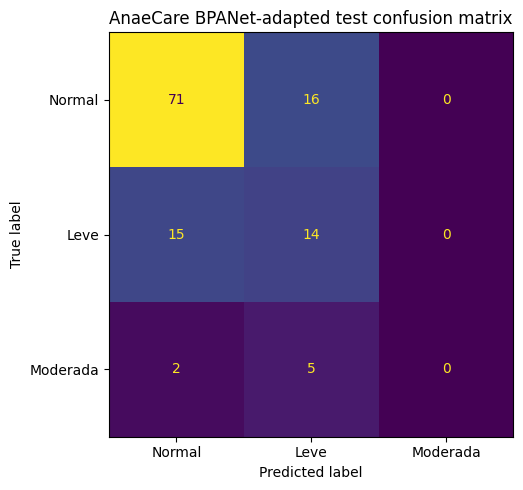

              precision    recall  f1-score   support

      Normal       0.81      0.82      0.81        87
        Leve       0.40      0.48      0.44        29
    Moderada       0.00      0.00      0.00         7

    accuracy                           0.69       123
   macro avg       0.40      0.43      0.42       123
weighted avg       0.66      0.69      0.68       123



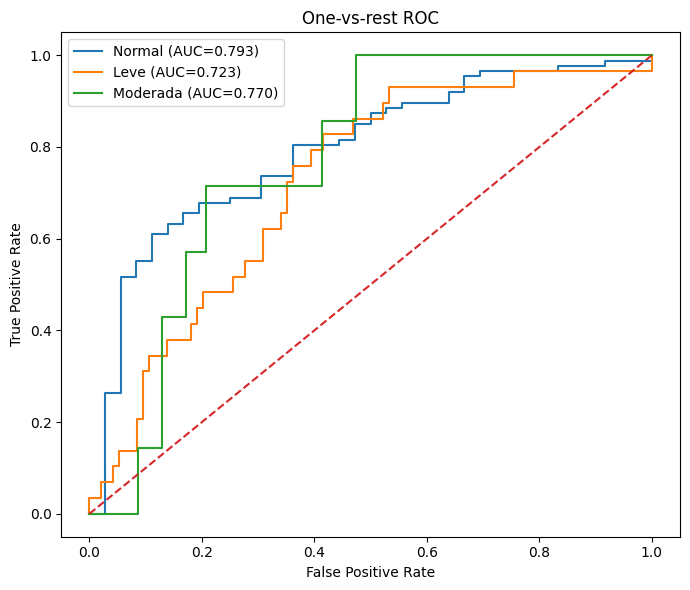

Saved all outputs to: /kaggle/working/AnaeCare_BPAnet_results
Best checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_best_validation.pt
Latest resumable checkpoint: /kaggle/working/AnaeCare_BPAnet_results/bpanet_last_epoch.pt


In [10]:
best_ckpt=torch.load(BEST_CKPT,map_location=DEVICE,weights_only=False)
model.load_state_dict(best_ckpt['model_state_dict']); model.eval()
test_metrics,y_test,y_pred,test_probs,hb_true,hb_pred=evaluate_model(model,test_loader,class_weights)
print('=== BPANet-adapted AnaeCare held-out test results ===')
display(pd.DataFrame([test_metrics]))
pd.DataFrame([test_metrics]).to_csv(os.path.join(RESULTS_DIR,'test_metrics.csv'),index=False)
cm=confusion_matrix(y_test,y_pred,labels=list(range(NUM_CLASSES)))
cm_df=pd.DataFrame(cm,index=[f'True {IDX_TO_CLASS[i]}' for i in range(NUM_CLASSES)],columns=[f'Pred {IDX_TO_CLASS[i]}' for i in range(NUM_CLASSES)])
cm_df.to_csv(os.path.join(RESULTS_DIR,'test_confusion_matrix.csv')); display(cm_df)
fig,ax=plt.subplots(figsize=(6,5)); ConfusionMatrixDisplay(cm,display_labels=[IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]).plot(ax=ax,values_format='d',colorbar=False); ax.set_title('AnaeCare BPANet-adapted test confusion matrix'); plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR,'test_confusion_matrix.png'),dpi=160); plt.show()
report=classification_report(y_test,y_pred,labels=list(range(NUM_CLASSES)),target_names=[IDX_TO_CLASS[i] for i in range(NUM_CLASSES)],output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv(os.path.join(RESULTS_DIR,'per_class_report.csv'))
print(classification_report(y_test,y_pred,labels=list(range(NUM_CLASSES)),target_names=[IDX_TO_CLASS[i] for i in range(NUM_CLASSES)],zero_division=0))
try:
    ybin=label_binarize(y_test,classes=list(range(NUM_CLASSES)))
    fig,ax=plt.subplots(figsize=(7,6))
    for c in range(NUM_CLASSES):
        if len(np.unique(ybin[:,c]))<2: continue
        fpr,tpr,_=roc_curve(ybin[:,c],test_probs[:,c]); ax.plot(fpr,tpr,label=f'{IDX_TO_CLASS[c]} (AUC={auc(fpr,tpr):.3f})')
    ax.plot([0,1],[0,1],'--'); ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.set_title('One-vs-rest ROC'); ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR,'test_roc.png'),dpi=160); plt.show()
except Exception as e: print('ROC plot skipped:',repr(e))

manifest={
 'paper':'Lin et al., Deep Learning-Based Model for Non-invasive Hemoglobin Estimation via Body Parts Images',
 'doi':'10.1007/s10278-024-01209-4','paper_url':'https://pmc.ncbi.nlm.nih.gov/articles/PMC11950610/',
 'status':'BPANet methodology adapted to AnaeCare paired multimodal data; not an exact reproduction of authors original code',
 'core_method':['ImageNet-pretrained ResNet-50','CSA after Stage 1 and before Stage 2','age and sex features','one-hot modality/body-part tags','external-attention-style Fusion Attention','Hb regression + 48-bin Hb classification dual loss','morphological opening preprocessing'],
 'AnaeCare_adaptations':['YEMAS and PALMAS sampled frame sequences pooled by Bi-LSTM','three paired modality tokens fused jointly','additional Normal/Leve/Moderada classification head and weighted CE loss'],
 'paths':{'csv':SPLIT_CSV_PATH,'metadata':METADATA_CSV_PATH,'yemas':YEMAS_DIR,'palmas':PALMAS_DIR,'unas':UNAS_DIR},
 'split_sizes':{'train':len(train_df),'validation':len(val_df),'test':len(test_df)},
 'settings':{'epochs':EPOCHS,'batch_size':BATCH_SIZE,'lr':LEARNING_RATE,'alpha':BPANET_ALPHA,'hb_bins':BPANET_HB_BINS,'class_loss_weight':CLASS_LOSS_WEIGHT},
 'best_checkpoint':BEST_CKPT,'latest_checkpoint':LAST_CKPT,'test_metrics':{k:float(v) for k,v in test_metrics.items()}}
with open(os.path.join(RESULTS_DIR,'methodology_manifest.json'),'w') as f: json.dump(manifest,f,indent=2)
print('Saved all outputs to:',RESULTS_DIR)
print('Best checkpoint:',BEST_CKPT); print('Latest resumable checkpoint:',LAST_CKPT)


## Step 10 — Package outputs

This final cell creates a ZIP of the metrics, plots, training history, manifest, and checkpoints in `/kaggle/working`.

In [11]:
import zipfile
ZIP_PATH='/kaggle/working/AnaeCare_BPANet_results.zip'
with zipfile.ZipFile(ZIP_PATH,'w',zipfile.ZIP_DEFLATED) as z:
    for root,dirs,files in os.walk(RESULTS_DIR):
        for name in files:
            path=os.path.join(root,name); z.write(path,arcname=os.path.relpath(path,RESULTS_DIR))
print('Results ZIP:',ZIP_PATH)
print('Notebook cells:',len([c for c in get_ipython().user_ns.get('In',[]) if c]))


Results ZIP: /kaggle/working/AnaeCare_BPANet_results.zip
Notebook cells: 11
